# Behavioral Decision-Making and Computational Modeling

This notebook analyzes trial-level behavior from a probabilistic four-option learning task. The workflow covers data quality checks, block-wise performance, reaction time, confidence, learning trajectories, and individual-level Q-learning model fitting.

The analysis dataset contains 40 anonymized participants with 105 trials each. The separately collected pilot data from the PsychoPy implementation are stored under `data/pilot_data/` and are not mixed into this analysis.


# Behavioral Dataset Inspection and Quality Control

### Loading the Behavioral Dataset

In [1]:
# Import required libraries for loading, organizing, and inspecting behavioral data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import ast
from pathlib import Path

# Resolve the repository root when Jupyter is started from the root or analysis folder.
CURRENT_DIR = Path.cwd()
if (CURRENT_DIR / "analysis").is_dir() and (CURRENT_DIR / "experiment").is_dir():
    PROJECT_ROOT = CURRENT_DIR
else:
    PROJECT_ROOT = CURRENT_DIR.parent

data_path = PROJECT_ROOT / "data"
RESULTS_FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
RESULTS_TABLES_DIR = PROJECT_ROOT / "results" / "tables"

RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_TABLES_DIR.mkdir(parents=True, exist_ok=True)


### Combining Participant Records

In [3]:
# Store all participant datasets
all_data = []

# Load participant files generated by the included PsychoPy experiment.
for gender in ["Male", "Female"]:

    folder_path = os.path.join(data_path, gender)
    files = sorted(glob.glob(os.path.join(folder_path, "*.csv")))

    for file in files:

        participant_data = pd.read_csv(file)

        # Extract the anonymous participant ID from the file name.
        participant_id = os.path.basename(file).replace(".csv", "")
        participant_data["participant_id"] = participant_id

        # The parent folder identifies the participant group.
        participant_data["gender"] = gender

        all_data.append(participant_data)

# Provide an actionable message when no generated participant files are available.
if not all_data:
    raise FileNotFoundError(
        "No participant CSV files were found. Run experiment/run_experiment.py "
        "to generate data under data/Male/ or data/Female/, then rerun this notebook."
    )

# Combine all participant datasets.
data = pd.concat(
    all_data,
    ignore_index=True
)

data.head()


,trial,choice,outcome,choice_rt,confidence_level,confidence_rt,next_trial_rt,card probs,participant_id,gender
0,0,1,win,11.063804,1,2.128321,3.875723,"[0.7, 0.4, 0.6, 0.5]",participant_004,Male
1,1,2,lose,4.385003,1,1.510157,1.326368,"[0.7, 0.4, 0.6, 0.5]",participant_004,Male
2,2,1,lose,2.928952,3,1.658494,1.027810,"[0.7, 0.4, 0.6, 0.5]",participant_004,Male
3,3,0,win,0.550552,4,1.267299,0.587826,"[0.7, 0.4, 0.6, 0.5]",participant_004,Male
4,4,3,win,2.212964,4,1.171982,1.070563,"[0.7, 0.4, 0.6, 0.5]",participant_004,Male


### Inspecting Dataset Dimensions

In [4]:
# Display the total number of trials and variables across all participants

print("Total number of trials:", data.shape[0])
print("Number of variables:", data.shape[1])

Total number of trials: 4200
Number of variables: 10


### Identifying Participants and Groups

In [5]:
# Count the number of participants in each gender group

participant_summary = (
    data.groupby("gender")["participant_id"]
    .nunique()
)

participant_summary

,participant_id
gender,
Female,21
Male,19


### Verifying Trial Counts

In [6]:
# Check the number of trials completed by each participant

trial_count = (
    data.groupby("participant_id")
    .size()
)

trial_count.describe()

,0
count,40.0
mean,105.0
std,0.0
min,105.0
25%,105.0
50%,105.0
75%,105.0
max,105.0


### Checking Missing Values

In [7]:
# Verify that each participant completed the expected number of trials

trial_count.value_counts()

,count
105,40


### Inspecting Variable Types

In [8]:
# Check missing values across the complete dataset

missing_values = data.isnull().sum()

missing_values

,0
trial,0
choice,0
outcome,0
choice_rt,0
confidence_level,0
confidence_rt,0
next_trial_rt,0
card probs,0
participant_id,0
gender,0


### Summarizing Dataset Variables

In [9]:
# Display variable types and dataset structure

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   trial             4200 non-null   int64  
 1   choice            4200 non-null   int64  
 2   outcome           4200 non-null   object 
 3   choice_rt         4200 non-null   float64
 4   confidence_level  4200 non-null   int64  
 5   confidence_rt     4200 non-null   float64
 6   next_trial_rt     4200 non-null   float64
 7   card probs        4200 non-null   object 
 8   participant_id    4200 non-null   object 
 9   gender            4200 non-null   object 
dtypes: float64(3), int64(3), object(4)
memory usage: 328.3+ KB


### Verifying Experimental Block Structure

In [10]:
# Generate a summary table of the dataset variables

data_summary = pd.DataFrame({
    "Variable": data.columns,
    "Data type": data.dtypes.values,
    "Missing values": data.isnull().sum().values,
    "Number of unique values": data.nunique().values
})


data_summary

,Variable,Data type,Missing values,Number of unique values
0,trial,int64,0,105
1,choice,int64,0,4
2,outcome,object,0,2
3,choice_rt,float64,0,4199
4,confidence_level,int64,0,5
5,confidence_rt,float64,0,4200
6,next_trial_rt,float64,0,4200
7,card probs,object,0,24
8,participant_id,object,0,40
9,gender,object,0,2


# Reward and Choice Performance Across Experimental Blocks

### Computing Block-Level Performance

In [16]:
# Define experimental blocks according to the task design
# Block 1: trials 0-14
# Block 2: trials 15-44
# Block 3: trials 45-104

def assign_block(trial):
    if trial < 15:
        return 1
    elif trial < 45:
        return 2
    else:
        return 3

data["block"] = data["trial"].apply(assign_block)

# Check the number of trials in each block

data["block"].value_counts().sort_index()

,count
block,
1,600
2,1200
3,2400


In [17]:
# Calculate block-level performance measures for each participant

# Define optimal reward probability for each trial
data["max_card_prob"] = data["card probs"].apply(
    lambda x: max(ast.literal_eval(x)) if isinstance(x, str) else max(x)
)

# Extract probability of selected card
data["selected_card_prob"] = data.apply(
    lambda row: ast.literal_eval(row["card probs"])[int(row["choice"])]
    if isinstance(row["card probs"], str)
    else row["card probs"][int(row["choice"])],
    axis=1
)

# Define optimal choice
data["optimal_choice"] = (
    data["selected_card_prob"] == data["max_card_prob"]
)

# Calculate performance measures per participant and block
block_performance = (
    data.groupby(
        ["participant_id", "gender", "block"]
    )
    .agg(
        reward_rate=("outcome", lambda x: (x=="win").mean()),
        optimal_choice_rate=("optimal_choice", "mean"),
        trials=("trial", "count")
    )
    .reset_index()
)

block_performance.head()

,participant_id,gender,block,reward_rate,optimal_choice_rate,trials
0,participant_001,Male,1,0.400000,0.466667,15
1,participant_001,Male,2,0.533333,0.033333,30
2,participant_001,Male,3,0.583333,0.833333,60
3,participant_0010,Male,1,0.600000,0.466667,15
4,participant_0010,Male,2,0.566667,0.300000,30


### Summarizing Performance Across Blocks

In [18]:
# Calculate group-level summary across blocks

performance_summary = (
    block_performance
    .groupby("block")
    .agg(
        mean_reward_rate=("reward_rate","mean"),
        sd_reward_rate=("reward_rate","std"),
        mean_optimal_choice=("optimal_choice_rate","mean"),
        sd_optimal_choice=("optimal_choice_rate","std")
    )
    .reset_index()
)

performance_summary

,block,mean_reward_rate,sd_reward_rate,mean_optimal_choice,sd_optimal_choice
0,1,0.548333,0.118382,0.286667,0.170269
1,2,0.608333,0.108539,0.403333,0.247011
2,3,0.597083,0.077523,0.397083,0.196330


### Visualizing Reward Rate

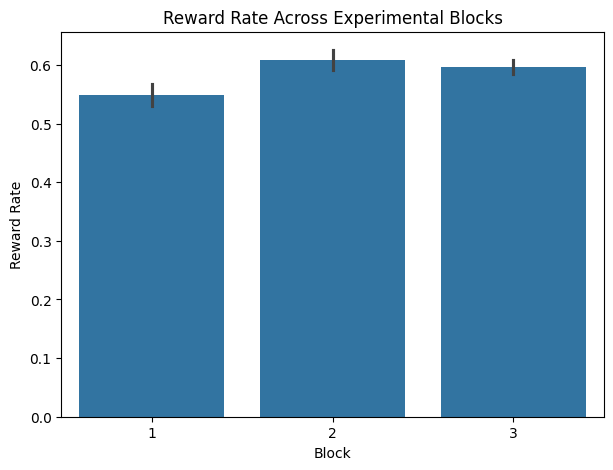

In [27]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=block_performance,
    x="block",
    y="reward_rate",
    errorbar="se"
)


plt.title("Reward Rate Across Experimental Blocks")
plt.xlabel("Block")
plt.ylabel("Reward Rate")

plt.savefig(
    RESULTS_FIGURES_DIR / "reward_rate_blocks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Visualizing Optimal Choice Rate

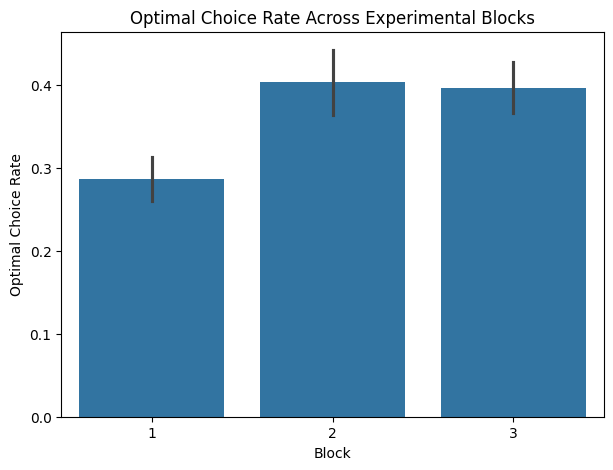

In [28]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=block_performance,
    x="block",
    y="optimal_choice_rate",
    errorbar="se"
)


plt.title("Optimal Choice Rate Across Experimental Blocks")
plt.xlabel("Block")
plt.ylabel("Optimal Choice Rate")

plt.savefig(
    RESULTS_FIGURES_DIR / "optimal_choice_blocks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Testing Reward-Rate Differences

In [22]:
from scipy.stats import friedmanchisquare


reward_b1 = block_performance[
    block_performance["block"] == 1
]["reward_rate"]

reward_b2 = block_performance[
    block_performance["block"] == 2
]["reward_rate"]

reward_b3 = block_performance[
    block_performance["block"] == 3
]["reward_rate"]


friedman_reward = friedmanchisquare(
    reward_b1,
    reward_b2,
    reward_b3
)


friedman_reward

FriedmanchisquareResult(statistic=np.float64(2.844155844155856), pvalue=np.float64(0.2412122754751037))

### Testing Optimal-Choice Differences

In [23]:
optimal_b1 = block_performance[
    block_performance["block"] == 1
]["optimal_choice_rate"]

optimal_b2 = block_performance[
    block_performance["block"] == 2
]["optimal_choice_rate"]

optimal_b3 = block_performance[
    block_performance["block"] == 3
]["optimal_choice_rate"]


friedman_optimal = friedmanchisquare(
    optimal_b1,
    optimal_b2,
    optimal_b3
)


friedman_optimal

FriedmanchisquareResult(statistic=np.float64(6.679738562091551), pvalue=np.float64(0.03544159030642965))

### Saving Block-Level Results

In [24]:
block_performance.to_csv(
    RESULTS_TABLES_DIR / "block_performance_results.csv",
    index=False
)

performance_summary.to_csv(
    RESULTS_TABLES_DIR / "block_summary_results.csv",
    index=False
)

### Pairwise Comparisons with Bonferroni Adjustment

In [25]:
# Perform pairwise Wilcoxon signed-rank tests between blocks
# with Bonferroni correction for multiple comparisons

from scipy.stats import wilcoxon
from itertools import combinations

# Create a wide-format dataframe
# Each row represents one participant and each column represents one block

optimal_wide = block_performance.pivot(
    index="participant_id",
    columns="block",
    values="optimal_choice_rate"
)

optimal_wide.head()

block,1,2,3
participant_id,,,
participant_001,0.466667,0.033333,0.833333
participant_0010,0.466667,0.300000,0.300000
participant_0011,0.200000,0.666667,0.166667
participant_0012,0.200000,0.366667,0.400000
participant_0013,0.200000,0.200000,0.266667


In [26]:
# Perform pairwise comparisons between experimental blocks

pairs = list(combinations([1, 2, 3], 2))

results = []


for block1, block2 in pairs:

    stat, p = wilcoxon(
        optimal_wide[block1],
        optimal_wide[block2]
    )

    # Bonferroni correction
    corrected_p = min(p * len(pairs), 1.0)

    results.append({
        "Comparison": f"Block {block1} vs Block {block2}",
        "Statistic": stat,
        "p_value": p,
        "Bonferroni_corrected_p": corrected_p
    })


posthoc_results = pd.DataFrame(results)


posthoc_results

,Comparison,Statistic,p_value,Bonferroni_corrected_p
0,Block 1 vs Block 2,196.5,0.031951,0.095853
1,Block 1 vs Block 3,165.5,0.001728,0.005185
2,Block 2 vs Block 3,369.5,0.988425,1.000000


Bonferroni-adjusted p-values are bounded between 0 and 1. Therefore, the adjusted value for Block 2 versus Block 3 is reported as 1.000 rather than the unbounded product of the raw p-value and the number of comparisons.


# Reaction-Time Analysis

### Calculating Participant-Level Reaction Times

In [29]:
# Calculate mean reaction time for each participant and block

rt_by_block = (
    data.groupby(
        ["participant_id", "gender", "block"]
    )
    .agg(
        mean_choice_rt=("choice_rt", "mean"),
        trials=("choice_rt", "count")
    )
    .reset_index()
)

rt_by_block.head()

,participant_id,gender,block,mean_choice_rt,trials
0,participant_001,Male,1,1.467795,15
1,participant_001,Male,2,0.965655,30
2,participant_001,Male,3,0.664039,60
3,participant_0010,Male,1,1.857564,15
4,participant_0010,Male,2,0.843751,30


### Summarizing Reaction Time

In [30]:
rt_summary = (
    rt_by_block
    .groupby("block")
    .agg(
        mean_RT=("mean_choice_rt", "mean"),
        sd_RT=("mean_choice_rt", "std")
    )
    .reset_index()
)

rt_summary

,block,mean_RT,sd_RT
0,1,2.879677,1.224175
1,2,1.574562,0.736396
2,3,1.100917,0.559675


### Visualizing Reaction Time

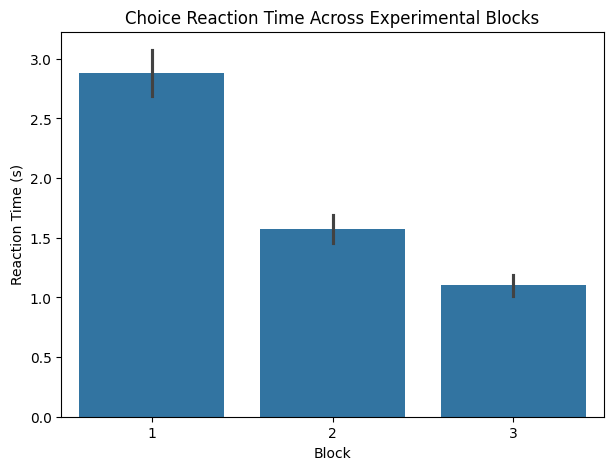

In [31]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=rt_by_block,
    x="block",
    y="mean_choice_rt",
    errorbar="se"
)

plt.title("Choice Reaction Time Across Experimental Blocks")
plt.xlabel("Block")
plt.ylabel("Reaction Time (s)")

plt.savefig(
    RESULTS_FIGURES_DIR / "reaction_time_blocks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Testing Reaction-Time Differences Across Blocks

In [32]:
rt_b1 = rt_by_block[
    rt_by_block["block"] == 1
]["mean_choice_rt"]

rt_b2 = rt_by_block[
    rt_by_block["block"] == 2
]["mean_choice_rt"]

rt_b3 = rt_by_block[
    rt_by_block["block"] == 3
]["mean_choice_rt"]

friedman_rt = friedmanchisquare(
    rt_b1,
    rt_b2,
    rt_b3
)

friedman_rt

FriedmanchisquareResult(statistic=np.float64(68.45000000000005), pvalue=np.float64(1.3685836800547124e-15))

### Comparing Reaction Time by Choice Type

In [33]:
rt_choice_type = (
    data.groupby("optimal_choice")
    .agg(
        mean_RT=("choice_rt", "mean"),
        sd_RT=("choice_rt", "std"),
        trials=("choice_rt", "count")
    )
    .reset_index()
)

rt_choice_type

,optimal_choice,mean_RT,sd_RT,trials
0,False,1.662518,1.994233,2591
1,True,1.213111,1.484535,1609


### Testing Reaction-Time Differences by Choice Type

In [34]:
from scipy.stats import mannwhitneyu

optimal_rt = data[
    data["optimal_choice"] == True
]["choice_rt"]

nonoptimal_rt = data[
    data["optimal_choice"] == False
]["choice_rt"]

mannwhitneyu(
    optimal_rt,
    nonoptimal_rt,
    alternative="two-sided"
)

MannwhitneyuResult(statistic=np.float64(1702386.5), pvalue=np.float64(1.5069375605268406e-23))

# Confidence and Metacognitive Measures

### Comparing Confidence by Choice Type

In [35]:
confidence_summary = (
    data.groupby("optimal_choice")
    .agg(
        mean_confidence=("confidence_level", "mean"),
        sd_confidence=("confidence_level", "std"),
        trials=("confidence_level", "count")
    )
    .reset_index()
)

confidence_summary

,optimal_choice,mean_confidence,sd_confidence,trials
0,False,3.115014,1.316912,2591
1,True,3.508390,1.292953,1609


### Visualizing Confidence

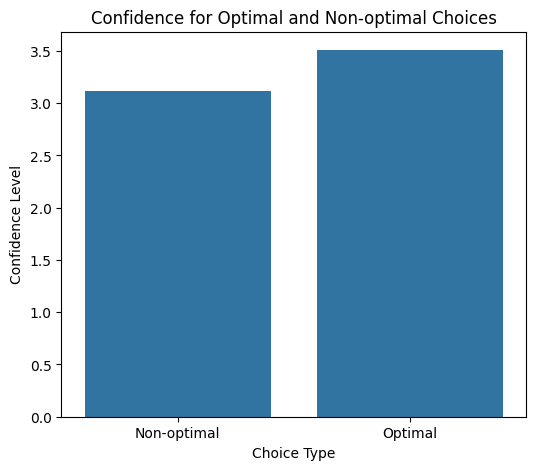

In [36]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=confidence_summary,
    x="optimal_choice",
    y="mean_confidence",
    errorbar="se"
)

plt.xticks(
    [0,1],
    ["Non-optimal", "Optimal"]
)

plt.xlabel("Choice Type")
plt.ylabel("Confidence Level")

plt.title(
    "Confidence for Optimal and Non-optimal Choices"
)

plt.savefig(
    RESULTS_FIGURES_DIR / "confidence_optimal_vs_nonoptimal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Testing Confidence Differences

In [37]:
participant_confidence = (
    data.groupby(
        ["participant_id", "optimal_choice"]
    )
    ["confidence_level"]
    .mean()
    .reset_index()
)

confidence_pivot = (
    participant_confidence
    .pivot(
        index="participant_id",
        columns="optimal_choice",
        values="confidence_level"
    )
    .dropna()
)

confidence_pivot.columns = [
    "nonoptimal_confidence",
    "optimal_confidence"
]


confidence_pivot.head()

,nonoptimal_confidence,optimal_confidence
participant_id,,
participant_001,3.553191,4.103448
participant_0010,2.647887,3.647059
participant_0011,4.000000,4.121212
participant_0012,3.149254,3.789474
participant_0013,4.012500,3.920000


### Within-Participant Confidence Comparison

In [38]:
wilcoxon_test = wilcoxon(
    confidence_pivot["optimal_confidence"],
    confidence_pivot["nonoptimal_confidence"]
)

wilcoxon_test

WilcoxonResult(statistic=np.float64(145.0), pvalue=np.float64(0.0003680628083569196))

### Calculating the Operational Metacognitive Score

In [39]:
confidence_pivot["metacognitive_score"] = (
    confidence_pivot["optimal_confidence"]
    -
    confidence_pivot["nonoptimal_confidence"]
)


metacognitive_summary = (
    confidence_pivot["metacognitive_score"]
    .describe()
)


metacognitive_summary

,metacognitive_score
count,40.000000
mean,0.390968
std,0.608629
min,-0.800000
25%,-0.006667
50%,0.323612
75%,0.782132
max,2.448052


# Learning Trajectory

### Calculating Trial-Wise Optimal-Choice Rate

In [40]:
# Calculate mean optimal choice rate for each trial

trial_learning_curve = (
    data.groupby("trial")
    .agg(
        optimal_choice_rate=("optimal_choice", "mean"),
        trials=("optimal_choice", "count")
    )
    .reset_index()
)

trial_learning_curve.head()

,trial,optimal_choice_rate,trials
0,0,0.225,40
1,1,0.300,40
2,2,0.175,40
3,3,0.225,40
4,4,0.175,40


### Applying Moving-Average Smoothing

In [41]:
window = 10

trial_learning_curve["smoothed_optimal_choice"] = (
    trial_learning_curve["optimal_choice_rate"]
    .rolling(
        window=window,
        min_periods=1
    )
    .mean()
)

trial_learning_curve.head()

,trial,optimal_choice_rate,trials,smoothed_optimal_choice
0,0,0.225,40,0.225000
1,1,0.300,40,0.262500
2,2,0.175,40,0.233333
3,3,0.225,40,0.231250
4,4,0.175,40,0.220000


### Visualizing the Learning Trajectory

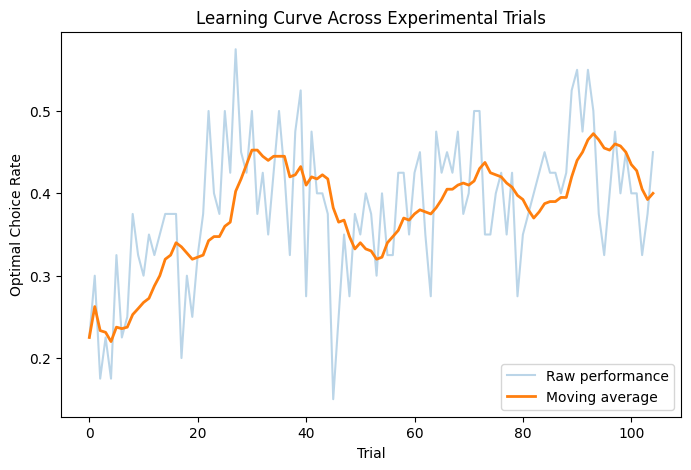

In [42]:
plt.figure(figsize=(8,5))

plt.plot(
    trial_learning_curve["trial"],
    trial_learning_curve["optimal_choice_rate"],
    alpha=0.3,
    label="Raw performance"
)

plt.plot(
    trial_learning_curve["trial"],
    trial_learning_curve["smoothed_optimal_choice"],
    linewidth=2,
    label="Moving average"
)

plt.xlabel("Trial")
plt.ylabel("Optimal Choice Rate")

plt.title(
    "Learning Curve Across Experimental Trials"
)

plt.legend()

plt.savefig(
    RESULTS_FIGURES_DIR / "learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Comparing Early and Late Performance

In [43]:
early_trials = (
    data[data["trial"] < 15]
    .groupby("participant_id")
    ["optimal_choice"]
    .mean()
)

late_trials = (
    data[data["trial"] >= 90]
    .groupby("participant_id")
    ["optimal_choice"]
    .mean()
)

learning_comparison = pd.DataFrame({
    "early_performance": early_trials,
    "late_performance": late_trials
})

learning_comparison.head()

,early_performance,late_performance
participant_id,,
participant_001,0.466667,0.866667
participant_0010,0.466667,0.133333
participant_0011,0.200000,0.066667
participant_0012,0.200000,0.466667
participant_0013,0.200000,0.333333


### Testing Early-to-Late Change

In [44]:
learning_test = wilcoxon(
    learning_comparison["early_performance"],
    learning_comparison["late_performance"]
)

learning_test

WilcoxonResult(statistic=np.float64(170.0), pvalue=np.float64(0.0035842084419376967))

### Summarizing Early and Late Performance

In [45]:
learning_summary = pd.DataFrame({
    "phase": [
        "Early trials",
        "Late trials"
    ],
    "mean_optimal_choice": [
        learning_comparison["early_performance"].mean(),
        learning_comparison["late_performance"].mean()
    ],
    "sd": [
        learning_comparison["early_performance"].std(),
        learning_comparison["late_performance"].std()
    ]
})

learning_summary

,phase,mean_optimal_choice,sd
0,Early trials,0.286667,0.170269
1,Late trials,0.430000,0.267072


# Preparing Trial Sequences for Q-Learning

### Ordering Participant Trial Sequences

In [47]:
# Sort data by participant and trial
data_model = data.sort_values(
    [
        "participant_id",
        "trial"
    ]
).copy()

data_model.head()

,trial,choice,outcome,choice_rt,confidence_level,confidence_rt,next_trial_rt,card probs,participant_id,gender,max_card_prob,selected_card_prob,optimal_choice,block
525,0,0,win,3.022005,2,18.391225,1.946591,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.5,False,1
526,1,1,win,2.615905,2,1.581208,1.447163,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.7,True,1
527,2,2,lose,1.115585,2,1.381384,0.166312,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.4,False,1
528,3,3,lose,2.432534,2,1.846908,1.656060,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.6,False,1
529,4,0,lose,2.327662,3,1.946047,4.427664,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.5,False,1


### Encoding Outcomes as Numerical Rewards

In [48]:
# Convert outcomes into numerical rewards
data_model["reward"] = (
    data_model["outcome"]
    .map(
        {
            "win": 1,
            "lose": 0
        }
    )
)
data_model.head()

,trial,choice,outcome,choice_rt,confidence_level,confidence_rt,next_trial_rt,card probs,participant_id,gender,max_card_prob,selected_card_prob,optimal_choice,block,reward
525,0,0,win,3.022005,2,18.391225,1.946591,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.5,False,1,1
526,1,1,win,2.615905,2,1.581208,1.447163,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.7,True,1,1
527,2,2,lose,1.115585,2,1.381384,0.166312,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.4,False,1,0
528,3,3,lose,2.432534,2,1.846908,1.656060,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.6,False,1,0
529,4,0,lose,2.327662,3,1.946047,4.427664,"[0.5, 0.7, 0.4, 0.6]",participant_001,Male,0.7,0.5,False,1,0


### Defining the Q-Value Update Rule

In [49]:
def update_q_value(
    q_value,
    reward,
    alpha
):

    updated_value = (
        q_value +
        alpha * (reward - q_value)
    )

    return updated_value

### Inspecting a Single Participant's Q-Value Updates

In [50]:
# Select the first available participant for illustrating Q-value updates.
example_participant_id = data_model["participant_id"].iloc[0]
participant_data = data_model[
    data_model["participant_id"] == example_participant_id
]

# Initialize Q-values for four cards
Q = {
    0: 0.5,
    1: 0.5,
    2: 0.5,
    3: 0.5
}

alpha = 0.2

for _, trial in participant_data.iterrows():

    choice = trial["choice"]
    reward = trial["reward"]

    Q[choice] = update_q_value(
        Q[choice],
        reward,
        alpha
    )

Q

{0: 0.24576000000000003,
 1: 0.5601930538293658,
 2: 0.45656123054367265,
 3: 0.2944566566792837}

# Softmax Q-Learning

### Defining the Softmax Policy

In [51]:
def softmax(q_values, beta):
    exp_values = np.exp(
        beta * np.array(list(q_values.values()))
    )
    probabilities = (
        exp_values /
        np.sum(exp_values)
    )
    return probabilities

### Defining the Softmax Negative Log-Likelihood

In [53]:
from scipy.optimize import minimize

def q_learning_softmax_loglik(
    params,
    participant_data
):

    alpha, beta = params

    # Parameter constraints
    if alpha < 0 or alpha > 1 or beta < 0:
        return np.inf

    Q = {
        0:0.5,
        1:0.5,
        2:0.5,
        3:0.5
    }

    log_likelihood = 0


    for _, trial in participant_data.iterrows():

        choice = trial["choice"]
        reward = trial["reward"]

        probabilities = softmax(
            Q,
            beta
        )

        choice_probability = probabilities[int(choice)]


        log_likelihood += np.log(
            choice_probability + 1e-10
        )

        Q[choice] = update_q_value(
            Q[choice],
            reward,
            alpha
        )

    return -log_likelihood

### Fitting the Softmax Model

In [55]:
softmax_results = []

for participant_id in data_model["participant_id"].unique():

    participant_data = data_model[
        data_model["participant_id"] == participant_id
    ]

    result = minimize(
        q_learning_softmax_loglik,
        x0=[0.5, 1],
        args=(participant_data,),
        bounds=[
            (0,1),
            (0,None)
        ]
    )
    softmax_results.append(
        {
            "participant_id": participant_id,
            "alpha": result.x[0],
            "beta": result.x[1],
            "NLL": result.fun
        }
    )

softmax_results = pd.DataFrame(
    softmax_results
)

softmax_results.head()

,participant_id,alpha,beta,NLL
0,participant_001,0.341168,7.604604,68.183141
1,participant_0010,0.183119,4.532847,133.850920
2,participant_0011,1.000000,1.141334,134.154396
3,participant_0012,0.938884,2.519979,104.735211
4,participant_0013,0.000000,0.067274,145.560908


### Summarizing Softmax Parameters

In [56]:
softmax_results.describe()

,alpha,beta,NLL
count,40.000000,40.000000,40.000000
mean,0.440301,7.608399,114.172292
std,0.367239,15.772464,29.784789
min,0.000000,0.005204,53.787513
25%,0.111839,1.264617,89.850589
50%,0.363034,3.131024,125.057809
75%,0.818288,7.170499,142.055381
max,1.000000,98.638521,145.560908


# Epsilon-Greedy Q-Learning

### Defining the Epsilon-Greedy Policy

In [58]:
def epsilon_greedy_policy(
    q_values,
    epsilon
):

    n_actions = len(q_values)

    probabilities = np.ones(
        n_actions
    ) * (
        epsilon / n_actions
    )

    best_action = np.argmax(
        list(q_values.values())
    )


    probabilities[best_action] += (
        1 - epsilon
    )

    return probabilities

### Defining the Epsilon-Greedy Negative Log-Likelihood

In [60]:
def q_learning_epsilon_greedy_loglik(
    params,
    participant_data
):

    alpha, epsilon = params

    # Parameter constraints

    if (
        alpha < 0 or alpha > 1 or
        epsilon < 0 or epsilon > 1
    ):
        return np.inf

    Q = {
        0:0.5,
        1:0.5,
        2:0.5,
        3:0.5
    }

    log_likelihood = 0

    for _, trial in participant_data.iterrows():

        choice = trial["choice"]
        reward = trial["reward"]


        probabilities = epsilon_greedy_policy(
            Q,
            epsilon
        )

        choice_probability = probabilities[
            int(choice)
        ]

        log_likelihood += np.log(
            choice_probability + 1e-10
        )

        Q[choice] = update_q_value(
            Q[choice],
            reward,
            alpha
        )

    return -log_likelihood

### Fitting the Epsilon-Greedy Model

In [62]:
# Fit epsilon-greedy model for all participants

epsilon_results = []


for participant_id in data_model["participant_id"].unique():

    participant_data = data_model[
        data_model["participant_id"] == participant_id
    ]


    result = minimize(
        q_learning_epsilon_greedy_loglik,
        x0=[0.5,0.2],
        args=(participant_data,),
        bounds=[
            (0,1),
            (0,1)
        ]
    )


    epsilon_results.append(
        {
            "participant_id": participant_id,
            "alpha": result.x[0],
            "epsilon": result.x[1],
            "NLL": result.fun
        }
    )


epsilon_results = pd.DataFrame(
    epsilon_results
)


epsilon_results.head()

,participant_id,alpha,epsilon,NLL
0,participant_001,0.5,0.292064,80.466574
1,participant_0010,0.5,0.850794,142.330180
2,participant_0011,0.5,0.838095,141.778131
3,participant_0012,0.5,0.571428,121.142904
4,participant_0013,0.5,1.000000,145.560908


### Summarizing Epsilon-Greedy Parameters

In [63]:
epsilon_results.describe()

,alpha,epsilon,NLL
count,40.0,40.000000,40.000000
mean,0.5,0.692222,125.131479
std,0.0,0.249491,22.800367
min,0.5,0.253968,73.098080
25%,0.5,0.501587,112.784331
50%,0.5,0.723810,134.995977
75%,0.5,0.914286,144.461211
max,0.5,1.000000,145.560908


# Probabilistic UCB Q-Learning

### Defining the Deterministic UCB Policy

In [64]:
def ucb_policy(
    q_values,
    action_counts,
    trial_number,
    c
):

    ucb_values = []

    for action in q_values.keys():

        uncertainty = np.sqrt(
            np.log(trial_number + 1) /
            (action_counts[action] + 1)
        )

        value = (
            q_values[action]
            +
            c * uncertainty
        )

        ucb_values.append(value)

    probabilities = np.zeros(
        len(q_values)
    )

    best_action = np.argmax(
        ucb_values
    )

    probabilities[best_action] = 1

    return probabilities

### Defining the Probabilistic UCB Policy

In [66]:
def probabilistic_ucb_policy(
    q_values,
    action_counts,
    trial_number,
    c,
    beta=5
):

    ucb_values = []


    for action in q_values.keys():

        uncertainty = np.sqrt(
            np.log(trial_number + 1) /
            (action_counts[action] + 1)
        )

        value = (
            q_values[action]
            +
            c * uncertainty
        )

        ucb_values.append(value)


    exp_values = np.exp(
        beta * np.array(ucb_values)
    )


    probabilities = (
        exp_values /
        np.sum(exp_values)
    )


    return probabilities

### Defining the Probabilistic UCB Negative Log-Likelihood

In [69]:
def q_learning_ucb_loglik(
    params,
    participant_data
):

    alpha, c = params


    if (
        alpha < 0 or alpha > 1 or
        c < 0
    ):
        return np.inf


    Q = {
        0:0.5,
        1:0.5,
        2:0.5,
        3:0.5
    }


    action_counts = {
        0:0,
        1:0,
        2:0,
        3:0
    }


    log_likelihood = 0


    for _, trial in participant_data.iterrows():

        choice = trial["choice"]
        reward = trial["reward"]


        probabilities = probabilistic_ucb_policy(
            Q,
            action_counts,
            trial["trial"],
            c
        )


        choice_probability = probabilities[
            int(choice)
        ]


        log_likelihood += np.log(
            choice_probability + 1e-10
        )


        Q[choice] = update_q_value(
            Q[choice],
            reward,
            alpha
        )


        action_counts[choice] += 1


    return -log_likelihood

### Fitting the Probabilistic UCB Model

In [71]:
# Fit UCB model for all participants

ucb_results = []


for participant_id in data_model["participant_id"].unique():

    participant_data = data_model[
        data_model["participant_id"] == participant_id
    ]


    result = minimize(
        q_learning_ucb_loglik,
        x0=[0.5,1],
        args=(participant_data,),
        bounds=[
            (0,1),
            (0,None)
        ]
    )


    ucb_results.append(
        {
            "participant_id": participant_id,
            "alpha": result.x[0],
            "c": result.x[1],
            "NLL": result.fun
        }
    )


ucb_results = pd.DataFrame(
    ucb_results
)


ucb_results.head()

,participant_id,alpha,c,NLL
0,participant_001,0.447961,0.00000,71.231560
1,participant_0010,0.167193,0.00000,133.895499
2,participant_0011,0.087792,0.00000,138.401126
3,participant_0012,0.536761,2.42237,101.558812
4,participant_0013,0.000000,0.00000,145.560908


### Summarizing UCB Parameters

In [72]:
ucb_results.describe()

,alpha,c,NLL
count,40.000000,40.000000,40.000000
mean,0.244647,0.375480,116.615797
std,0.245233,0.661608,28.552073
min,0.000000,0.000000,60.210776
25%,0.025988,0.000000,93.130802
50%,0.155400,0.099553,128.074572
75%,0.494896,0.513306,143.188681
max,0.702698,3.278454,145.560908


# Information-Criterion-Based Model Comparison

### Calculating Model Comparison Metrics

In [73]:
# Number of observations per participant

n_trials = 105

k = 2   # number of parameters in each model

comparison = pd.DataFrame({

    "Model": [
        "Softmax",
        "Epsilon-Greedy",
        "UCB"
    ],

    "Mean_NLL": [
        softmax_results["NLL"].mean(),
        epsilon_results["NLL"].mean(),
        ucb_results["NLL"].mean()
    ]
})

comparison["Mean_LL"] = -comparison["Mean_NLL"]

comparison["AIC"] = (
    2*k -
    2*comparison["Mean_LL"]
)

comparison["BIC"] = (
    k*np.log(n_trials) -
    2*comparison["Mean_LL"]
)

comparison

,Model,Mean_NLL,Mean_LL,AIC,BIC
0,Softmax,114.172292,-114.172292,232.344584,237.652505
1,Epsilon-Greedy,125.131479,-125.131479,254.262957,259.570878
2,UCB,116.615797,-116.615797,237.231593,242.539514


### Visualizing BIC Values

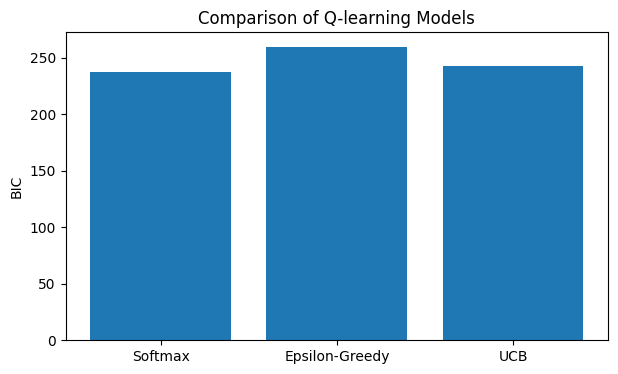

In [74]:
plt.figure(figsize=(7,4))


plt.bar(
    comparison["Model"],
    comparison["BIC"]
)


plt.ylabel(
    "BIC"
)

plt.title(
    "Comparison of Q-learning Models"
)


plt.savefig(
    RESULTS_FIGURES_DIR / "model_comparison_BIC.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

# Interpretation, Model Comparison, and Study Limitations

## Main behavioral findings

The 40-participant analysis dataset contains 4,200 trial-level observations. The reported block-level means were:

| Block | Mean reward rate | SD reward rate | Mean optimal-choice rate | SD optimal-choice rate |
|---|---:|---:|---:|---:|
| 1 (15 trials) | 0.548 | 0.118 | 0.287 | 0.170 |
| 2 (30 trials) | 0.608 | 0.109 | 0.403 | 0.247 |
| 3 (60 trials) | 0.597 | 0.078 | 0.397 | 0.196 |

The Friedman test did not detect a statistically significant block effect for reward rate (χ²(2) = 2.844, p = 0.241). The block effect for optimal-choice rate was statistically significant (χ²(2) = 6.680, p = 0.035). The pairwise Wilcoxon comparisons, with Bonferroni adjustment, showed an adjusted p-value of 0.005 for Block 1 versus Block 3; the adjusted p-values for the other comparisons were 0.096 and 1.000.

Mean choice reaction time decreased from 2.880 s in Block 1 to 1.575 s in Block 2 and 1.101 s in Block 3. The Friedman test was significant (χ²(2) = 68.450, p < 0.001). The trial-level Mann–Whitney comparison between optimal and non-optimal choices was also significant (U = 1,702,386.5, p < 0.001), but it treats trials as independent observations. Since trials are nested within participants, this result should be interpreted cautiously.

Mean confidence was higher for optimal than non-optimal choices at the participant level (Wilcoxon signed-rank statistic = 145, p < 0.001). The reported operational metacognitive score—mean confidence on optimal choices minus mean confidence on non-optimal choices—was 0.391 (SD = 0.609). This score is a simple confidence-discrimination measure and is not equivalent to meta-d′ or another signal-detection-based metacognitive efficiency measure.

## Q-learning model comparison

The saved fit results were:

| Model | Mean NLL | Mean log-likelihood | AIC | BIC |
|---|---:|---:|---:|---:|
| Softmax Q-learning | 114.172 | -114.172 | 232.345 | 237.653 |
| Epsilon-Greedy Q-learning | 125.131 | -125.131 | 254.263 | 259.571 |
| Probabilistic UCB variant | 116.616 | -116.616 | 237.232 | 242.540 |

Among the implemented models, Softmax Q-learning had the lowest mean NLL, AIC, and BIC. This supports the report's comparative conclusion for these specific implementations and this dataset; it does not establish that Softmax is universally the best account of human decision-making.

## Implementation details that affect interpretation

- The analysis dataset uses 105 trials per participant and defines blocks as 15, 30, and 60 trials. The separate PsychoPy pilot implementation uses 15, 30, and 45 trials (90 trials total). These are distinct task versions and must not be pooled without a protocol-level reconciliation.
- In the behavioral data, `choice` is a zero-based screen-position index. The `card probs` field stores the reward probabilities in the current screen-position order. The descriptive optimal-choice calculation uses both fields to identify whether the selected position had the highest probability.
- The Q-learning likelihood functions update one Q-value per screen-position index and do not use the trial-specific `card probs` mapping or reset values at block boundaries. Because card positions are rearranged between blocks, the action-to-reward mapping is not stationary across the full sequence. Consequently, the reported Q-learning comparison should be treated as an exploratory comparison of the implemented models, not as a definitive cognitive account of stable card identities.
- The Epsilon-Greedy policy uses `argmax` with deterministic first-index tie breaking. When Q-values are tied, the first action receives the exploitation component. The fitted learning-rate parameter remained at its initial value of 0.5 for all participants, indicating that this parameter was not effectively identified by the current objective and policy implementation.
- The UCB likelihood uses a softmax transformation of UCB scores with a fixed inverse-temperature value of 5. It is therefore a probabilistic UCB variant rather than the deterministic UCB policy defined in the unused helper function.
- The reported AIC and BIC are calculated from the mean participant-level NLL with two fitted parameters and 105 observations per participant. They are mean participant-level criteria, not criteria computed from one pooled likelihood over all 4,200 trials.
- The Mann–Whitney U test compares trial-level reaction times without accounting for within-participant dependence. A participant-level or mixed-effects analysis would be more appropriate for inferential claims.
- The confidence difference score is descriptive and should not be interpreted as a full metacognitive-efficiency estimate.

## Conclusion

The descriptive and inferential analyses indicate that optimal-choice rate and response speed changed across the three blocks, while reward rate did not show a statistically significant block effect. Participants also reported higher confidence on trials classified as optimal. In the exploratory model comparison, Softmax Q-learning achieved the best information-criterion values among the three implemented variants.

The most important qualification is that the current Q-learning implementation treats screen positions as stable actions even though the reward-probability mapping changes between blocks. A follow-up analysis should encode the action identity consistently with the task design before making strong claims about latent learning strategies.
